# Algorithm Analysis & Visualization
## Practical Laboratory Based on Rosen, *Discrete Mathematics and Its Applications*, 8th Edition — Chapter 3

**Course:** Algorithm Analysis  
**Notebook:** `Algorithm_Analysis.ipynb`  
**Language:** Python 3

---

### Project objectives

This notebook studies the topics in Chapter 3 through explanations, pseudocode, implementations, correctness checks, operation counting and experiments.

1. **3.1 Algorithms:** algorithm definition and properties; maximum element; linear and binary search; bubble and insertion sort; naive string matching; greedy cashier and activity-scheduling algorithms; halting problem.
2. **3.2 The Growth of Functions:** Big-O, Big-Omega, Big-Theta, standard growth rates and combinations of functions.
3. **3.3 Complexity of Algorithms:** operation-count analysis, searching and sorting complexity, matrix multiplication, algorithmic paradigms, brute force and tractability.

> **Scope note:** The notebook follows the uploaded Rosen Chapter 3. Some extra visualizations and test helpers are practical teaching aids; they are identified as such. The textbook's Section 3.3 emphasizes time complexity and does not develop a detailed space-complexity treatment.

### How to use this notebook

Run the cells from top to bottom. The benchmark timings depend on your computer, Python version, operating system and current system load. The theoretical complexity classifications do not depend on those timings.

## 0. Environment and reproducibility

The notebook uses standard Python libraries. Matplotlib and NumPy are used for plots and numerical experiments. If they are unavailable, install them in your notebook environment:

```bash
pip install matplotlib numpy pandas
```

In [1]:
import math
import random
import statistics
import time
from collections import Counter
from typing import Iterable, Sequence

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print("Python algorithm-analysis laboratory is ready.")

Python algorithm-analysis laboratory is ready.


# Part I — Section 3.1: Algorithms

## 1. Introduction and definition

An **algorithm** is a finite sequence of precise instructions for performing a computation or solving a problem.

An algorithm description should be independent of a particular programming language where possible. Pseudocode is useful because it communicates the steps without requiring Python, C++ or Java syntax.

### General properties of algorithms

| Property | Meaning |
|---|---|
| Input | Values supplied from a specified set |
| Output | Result produced by the procedure |
| Definiteness | Every instruction is precisely defined |
| Correctness | The procedure produces the required result |
| Finiteness | It terminates after a finite number of steps |
| Effectiveness | Each step can be carried out in finite time |
| Generality | It applies to all valid instances of the problem |

### Example: maximum element

**Problem:** Given a non-empty finite sequence of integers, return its largest element.

**Pseudocode**

```text
max := first element
for each remaining element x:
    if x > max:
        max := x
return max
```

The loop examines every remaining element. After processing each element, `maximum` stores the largest value seen so far.

In [2]:
def maximum_element(values):
    """Return the maximum value in a non-empty iterable of comparable values."""
    iterator = iter(values)
    try:
        current_max = next(iterator)
    except StopIteration:
        raise ValueError("maximum_element requires at least one value")

    comparisons = 0
    for value in iterator:
        comparisons += 1
        if value > current_max:
            current_max = value

    return current_max, comparisons


sample = [8, 4, 11, 3, 10]
result, comparisons = maximum_element(sample)
print("Input:", sample)
print("Maximum:", result)
print("Comparisons:", comparisons)

Input: [8, 4, 11, 3, 10]
Maximum: 11
Comparisons: 4


### Trace table

The trace makes the algorithm's state visible after each input value.

In [3]:
def trace_maximum(values):
    if not values:
        raise ValueError("Input must be non-empty")
    current_max = values[0]
    rows = [{"position": 1, "value": values[0], "maximum_after_step": current_max,
             "updated": True}]
    for index, value in enumerate(values[1:], start=2):
        updated = value > current_max
        if updated:
            current_max = value
        rows.append({"position": index, "value": value,
                     "maximum_after_step": current_max, "updated": updated})
    return pd.DataFrame(rows)

trace_maximum([8, 4, 11, 3, 10])

,position,value,maximum_after_step,updated
0,1,8,8,True
1,2,4,8,False
2,3,11,11,True
3,4,3,11,False
4,5,10,11,False


### Correctness idea

After processing the first $i$ values, the variable `current_max` equals the maximum of those first $i$ values.

- **Initialization:** For $i=1$, the first value is the maximum of the one-element prefix.
- **Maintenance:** The next value either exceeds the current maximum, in which case it becomes the new maximum, or it does not, in which case the current maximum remains correct.
- **Termination:** After all $n$ values have been processed, the variable is the maximum of the entire sequence.

For $n$ input values, this implementation performs exactly $n-1$ comparisons. Its running time is $\Theta(n)$.

## 2. Searching algorithms

The general search problem is to locate a target in a list or report that it is absent.

### 2.1 Linear (sequential) search

Linear search checks elements in order until the target is found or the list ends.

**Pseudocode**

```text
for each position i from 0 to n - 1:
    if A[i] equals target:
        return i
return -1
```

- Works on sorted and unsorted sequences.
- Best case: one comparison, $\Theta(1)$.
- Worst case: target is last or absent, $n$ comparisons, $\Theta(n)$.

In [4]:
def linear_search(values, target):
    """Return (index, comparisons); index is -1 when target is absent."""
    comparisons = 0
    for index, value in enumerate(values):
        comparisons += 1
        if value == target:
            return index, comparisons
    return -1, comparisons


data = [14, 7, 22, 9, 31, 5]
print("Found:", linear_search(data, 31))
print("Not found:", linear_search(data, 100))

Found: (4, 5)
Not found: (-1, 6)


### 2.2 Binary search

Binary search requires the input sequence to be sorted. It compares the target with a middle element and discards half of the remaining interval at each iteration.

**Pseudocode**

```text
low := 0
high := n - 1
while low <= high:
    middle := floor((low + high) / 2)
    if A[middle] = target:
        return middle
    if A[middle] < target:
        low := middle + 1
    else:
        high := middle - 1
return -1
```

The interval is approximately halved after each comparison, giving worst-case $\Theta(\log n)$ time.

In [5]:
def binary_search(sorted_values, target):
    """Iterative binary search. Input must be sorted in nondecreasing order."""
    low, high = 0, len(sorted_values) - 1
    comparisons = 0

    while low <= high:
        middle = (low + high) // 2
        comparisons += 1
        if sorted_values[middle] == target:
            return middle, comparisons
        comparisons += 1
        if sorted_values[middle] < target:
            low = middle + 1
        else:
            high = middle - 1

    return -1, comparisons


ordered = [1, 2, 3, 5, 6, 7, 8, 10, 12, 13, 15, 16, 18, 19, 20, 22]
print("Search for 19:", binary_search(ordered, 19))
print("Search for 4:", binary_search(ordered, 4))

Search for 19: (13, 5)
Search for 4: (-1, 8)


### Visual comparison of search paths

The following helper illustrates which positions are inspected. It is a visualization aid; the search functions above are the implementations used for operation counting.

In [6]:
def linear_search_trace(values, target):
    inspected = []
    for i, value in enumerate(values):
        inspected.append(i)
        if value == target:
            break
    return inspected

def binary_search_trace(values, target):
    low, high = 0, len(values) - 1
    inspected = []
    while low <= high:
        mid = (low + high) // 2
        inspected.append(mid)
        if values[mid] == target:
            break
        if values[mid] < target:
            low = mid + 1
        else:
            high = mid - 1
    return inspected

example = list(range(1, 32, 2))
target = 23
print("Linear positions:", linear_search_trace(example, target))
print("Binary positions:", binary_search_trace(example, target))

Linear positions: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]
Binary positions: [7, 11]


### Searching complexity summary

| Algorithm | Input condition | Best case | Worst case |
|---|---|---:|---:|
| Linear search | Any sequence | $\Theta(1)$ | $\Theta(n)$ |
| Binary search | Sorted sequence | $\Theta(1)$ | $\Theta(\log n)$ |

**Important:** Sorting a sequence solely to perform one binary search has a cost of its own. Binary search is especially useful when the data is already sorted or many searches will be performed on the same sorted data.

## 3. Sorting algorithms

Sorting arranges the elements of a list in a specified order. Rosen Chapter 3 introduces bubble sort and insertion sort.

### 3.1 Bubble sort

Bubble sort repeatedly compares adjacent elements and swaps them when they are in the wrong order. In the basic textbook version, the outer loop makes $n-1$ passes.

**Pseudocode**

```text
for i := 0 to n - 2:
    for j := 0 to n - i - 2:
        if A[j] > A[j + 1]:
            swap A[j], A[j + 1]
```

The basic version performs $n(n-1)/2$ comparisons, so its comparison count is $\Theta(n^2)$, including on already sorted input.

In [7]:
def bubble_sort(values):
    """Basic bubble sort corresponding to the textbook's nested-loop version."""
    a = list(values)
    comparisons = 0
    swaps = 0
    n = len(a)

    for i in range(n - 1):
        for j in range(n - i - 1):
            comparisons += 1
            if a[j] > a[j + 1]:
                a[j], a[j + 1] = a[j + 1], a[j]
                swaps += 1

    return a, {"comparisons": comparisons, "swaps": swaps}


bubble_input = [3, 2, 4, 1, 5]
print("Sorted:", bubble_sort(bubble_input))

Sorted: ([1, 2, 3, 4, 5], {'comparisons': 10, 'swaps': 4})


### Bubble sort pass-by-pass trace

In [8]:
def bubble_sort_pass_trace(values):
    a = list(values)
    pass_rows = []
    for pass_number in range(1, len(a)):
        swaps_this_pass = 0
        for j in range(len(a) - pass_number):
            if a[j] > a[j + 1]:
                a[j], a[j + 1] = a[j + 1], a[j]
                swaps_this_pass += 1
        pass_rows.append({
            "pass": pass_number,
            "array_after_pass": a.copy(),
            "swaps_in_pass": swaps_this_pass
        })
    return pd.DataFrame(pass_rows)

bubble_sort_pass_trace([3, 2, 4, 1, 5])

,pass,array_after_pass,swaps_in_pass
0,1,"[2, 3, 1, 4, 5]",2
1,2,"[2, 1, 3, 4, 5]",1
2,3,"[1, 2, 3, 4, 5]",1
3,4,"[1, 2, 3, 4, 5]",0


### 3.2 Insertion sort

Insertion sort maintains a sorted prefix. At each step it takes the next element and inserts it into the correct position in that prefix.

**Pseudocode**

```text
for j := 1 to n - 1:
    key := A[j]
    i := j - 1
    while i >= 0 and A[i] > key:
        A[i + 1] := A[i]
        i := i - 1
    A[i + 1] := key
```

- Best case: already sorted input; linear comparisons, $\Theta(n)$.
- Worst case: reverse-sorted input; quadratic work, $\Theta(n^2)$.

In [9]:
def insertion_sort(values):
    a = list(values)
    comparisons = 0
    shifts = 0

    for j in range(1, len(a)):
        key = a[j]
        i = j - 1
        while i >= 0:
            comparisons += 1
            if a[i] > key:
                a[i + 1] = a[i]
                shifts += 1
                i -= 1
            else:
                break
        a[i + 1] = key

    return a, {"comparisons": comparisons, "shifts": shifts}


insertion_input = [3, 2, 4, 1, 5]
print("Sorted:", insertion_sort(insertion_input))

Sorted: ([1, 2, 3, 4, 5], {'comparisons': 6, 'shifts': 4})


### Sorting comparison

| Algorithm | Best case | Average case | Worst case | Stable? |
|---|---:|---:|---:|---|
| Basic bubble sort | $\Theta(n^2)$ | $\Theta(n^2)$ | $\Theta(n^2)$ | Yes |
| Insertion sort | $\Theta(n)$ | $\Theta(n^2)$ | $\Theta(n^2)$ | Yes |

The basic bubble-sort version shown here does not use an early-termination flag. An optimized bubble sort can stop after a pass with no swaps; that is a separate variation and should not be confused with the basic textbook algorithm.

In [10]:
sort_cases = {
    "already sorted": list(range(1, 11)),
    "reverse sorted": list(range(10, 0, -1)),
    "mixed": [7, 2, 9, 1, 5, 3, 8, 4, 6, 0],
}

rows = []
for case_name, values in sort_cases.items():
    b_sorted, b_stats = bubble_sort(values)
    i_sorted, i_stats = insertion_sort(values)
    assert b_sorted == sorted(values)
    assert i_sorted == sorted(values)
    rows.append({
        "case": case_name,
        "bubble_comparisons": b_stats["comparisons"],
        "bubble_swaps": b_stats["swaps"],
        "insertion_comparisons": i_stats["comparisons"],
        "insertion_shifts": i_stats["shifts"],
    })

pd.DataFrame(rows)

,case,bubble_comparisons,bubble_swaps,insertion_comparisons,insertion_shifts
0,already sorted,45,0,9,0
1,reverse sorted,45,45,45,45
2,mixed,45,26,32,26


## 4. String matching: naive string matcher

The string-matching problem asks whether a pattern `P` occurs in a text `T`, and if so, at which positions.

The naive matcher checks the pattern at every possible shift in the text. At each shift, it compares pattern characters from left to right until a mismatch occurs or the full pattern matches.

**Pseudocode**

```text
for shift := 0 to n - m:
    j := 0
    while j < m and T[shift + j] = P[j]:
        j := j + 1
    if j = m:
        report shift
```

For text length $n$ and pattern length $m$, the worst-case number of character comparisons is at most $m(n-m+1)$, which is $O(nm)$.

In [11]:
def naive_string_match(text, pattern):
    """Return all zero-based match positions and character-comparison count."""
    if pattern == "":
        # Empty-pattern convention: it matches at every boundary.
        return list(range(len(text) + 1)), 0
    n, m = len(text), len(pattern)
    matches = []
    comparisons = 0

    for shift in range(n - m + 1):
        j = 0
        while j < m:
            comparisons += 1
            if text[shift + j] != pattern[j]:
                break
            j += 1
        if j == m:
            matches.append(shift)

    return matches, comparisons


text_value = "eceyeye"
pattern_value = "eye"
print("Text:", text_value)
print("Pattern:", pattern_value)
print("Matches and comparisons:", naive_string_match(text_value, pattern_value))

Text: eceyeye
Pattern: eye
Matches and comparisons: ([2, 4], 10)


### String-matching trace

In [12]:
def naive_string_match_trace(text, pattern):
    rows = []
    n, m = len(text), len(pattern)
    if m == 0:
        return pd.DataFrame(columns=["shift", "compared_text", "compared_pattern", "outcome"])
    for shift in range(n - m + 1):
        j = 0
        while j < m and text[shift + j] == pattern[j]:
            rows.append({
                "shift": shift,
                "text_position": shift + j,
                "text_character": text[shift + j],
                "pattern_character": pattern[j],
                "outcome": "match"
            })
            j += 1
        if j < m:
            rows.append({
                "shift": shift,
                "text_position": shift + j,
                "text_character": text[shift + j],
                "pattern_character": pattern[j],
                "outcome": "mismatch"
            })
    return pd.DataFrame(rows)

naive_string_match_trace("eceyeye", "eye")

,shift,text_position,text_character,pattern_character,outcome
0,0,0,e,e,match
1,0,1,c,y,mismatch
2,1,1,c,e,mismatch
3,2,2,e,e,match
4,2,3,y,y,match
5,2,4,e,e,match
6,3,3,y,e,mismatch
7,4,4,e,e,match
8,4,5,y,y,match
9,4,6,e,e,match


## 5. Greedy algorithms

A greedy algorithm makes a locally best choice at each step according to a specified criterion. A greedy choice does not automatically guarantee a globally optimal answer; the algorithm needs a proof for the problem and input assumptions.

### 5.1 Cashier's algorithm

For coin denominations listed from largest to smallest, repeatedly take as many coins of the current denomination as possible before moving to the next denomination.

Rosen demonstrates that the greedy cashier's algorithm is optimal for the denomination system consisting of quarters (25), dimes (10), nickels (5) and pennies (1). It is not optimal for every possible coin system.

In [13]:
def cashier_change(amount, denominations):
    """Greedy change-making. Denominations must be positive, descending integers."""
    if amount < 0:
        raise ValueError("amount must be non-negative")
    if any(c <= 0 for c in denominations):
        raise ValueError("coin denominations must be positive")
    if list(denominations) != sorted(denominations, reverse=True):
        raise ValueError("denominations must be in descending order")

    remaining = amount
    result = []
    for coin in denominations:
        count, remaining = divmod(remaining, coin)
        result.append((coin, count))

    if remaining != 0:
        raise ValueError("These denominations cannot represent the amount exactly")
    return result


us_coins = [25, 10, 5, 1]
change = cashier_change(67, us_coins)
print("67 cents:", change)
print("Total coins:", sum(count for _, count in change))

# A counterexample for an arbitrary denomination system:
print("Greedy with [4, 3, 1] for amount 6:", cashier_change(6, [4, 3, 1]))
print("Optimal solution for that example is 3 + 3 (2 coins).")

67 cents: [(25, 2), (10, 1), (5, 1), (1, 2)]
Total coins: 6
Greedy with [4, 3, 1] for amount 6: [(4, 1), (3, 0), (1, 2)]
Optimal solution for that example is 3 + 3 (2 coins).


### 5.2 Activity (talk) scheduling

Each activity has a start time and finish time. The goal is to select the largest possible set of mutually compatible activities in one room.

The greedy rule described in Rosen is: **choose the compatible activity with the earliest finish time**. Sort by finish time, select the first activity, then repeatedly select the next activity whose start time is at or after the finish time of the last selected activity.

In [14]:
def activity_selection(activities):
    """Activities are (start, finish, label); touching endpoints are compatible."""
    ordered = sorted(activities, key=lambda item: item[1])
    selected = []
    last_finish = float("-inf")

    for start, finish, label in ordered:
        if start >= last_finish:
            selected.append((start, finish, label))
            last_finish = finish

    return selected


talks = [
    (8, 12, "Talk 1"),
    (9, 10, "Talk 2"),
    (11, 12, "Talk 3"),
    (10, 11, "Talk 4"),
    (12, 13, "Talk 5"),
]
selected_talks = activity_selection(talks)
print("Selected talks:")
for talk in selected_talks:
    print(talk)

Selected talks:
(9, 10, 'Talk 2')
(10, 11, 'Talk 4')
(11, 12, 'Talk 3')
(12, 13, 'Talk 5')


### Greedy algorithm discussion

- A feasible solution satisfies the problem constraints.
- An optimal solution is the best feasible solution according to the objective.
- A greedy strategy needs a correctness argument; a plausible local choice is not itself a proof.
- For the cashier's algorithm, the textbook's optimality result is specific to the quarter/dime/nickel/penny system.
- For activity scheduling, earliest finishing time is the criterion that leads to an optimal maximum-size schedule under the stated compatibility rules.

## 6. The halting problem

The halting problem asks whether there is a general procedure that can decide, for every program and every input, whether that program eventually stops or runs forever.

Rosen presents the contradiction argument associated with Alan Turing:

1. Assume a hypothetical procedure `H(P, I)` correctly decides whether program `P` halts on input `I`.
2. Construct a program `K(P)` that does the opposite of what `H(P, P)` predicts.
3. Consider running `K` with itself as input.
4. If `H(K, K)` predicts that `K(K)` halts, the construction makes it loop forever.
5. If `H(K, K)` predicts that `K(K)` loops forever, the construction makes it halt.
6. Both possibilities contradict the assumed correctness of `H`.

Therefore, no such procedure can correctly decide the halting behavior of every program-input pair.

**Important:** A program running for a long time does not prove that it will never halt. This notebook does not attempt to build a universal halting decider; that is precisely what the theorem rules out.

# Part II — Section 3.2: The Growth of Functions

## 7. Why study growth rates?

The time needed by a program depends on the implementation, hardware and software environment. However, for a fixed algorithm, the number of basic operations as a function of input size helps describe how its resource use grows.

Asymptotic notation focuses on behavior for sufficiently large input sizes and abstracts away constant multipliers and lower-order terms.

## 8. Big-O notation

For functions $f$ and $g$, we say $f(x)=O(g(x))$ if there are positive constants $C$ and $k$ such that

\[

|f(x)| \le C|g(x)| \quad \text{whenever } x>k.

\]

Big-O gives an asymptotic upper bound.

### Example

Let $f(n)=3n^2+5n+7$. For $n\ge 1$,

\[

3n^2+5n+7 \le 3n^2+5n^2+7n^2=15n^2.

\]

Therefore, $f(n)=O(n^2)$, with one possible choice $C=15$, $k=1$.

In [15]:
def f_example(n):
    return 3*n**2 + 5*n + 7

for n in [1, 2, 5, 10, 100]:
    print(f"n={n:3d}, f(n)={f_example(n):8d}, 15n^2={15*n*n:8d}")

n=  1, f(n)=      15, 15n^2=      15
n=  2, f(n)=      29, 15n^2=      60
n=  5, f(n)=     107, 15n^2=     375
n= 10, f(n)=     357, 15n^2=    1500
n=100, f(n)=   30507, 15n^2=  150000


## 9. Standard growth rates

Common reference functions include:

| Function | Growth class |
|---|---|
| $1$ | Constant |
| $\log n$ | Logarithmic |
| $n$ | Linear |
| $n\log n$ | Linearithmic |
| $n^2$ | Quadratic |
| $n^3$ | Cubic |
| $a^n,\ a>1$ | Exponential |
| $n!$ | Factorial |

For the usual asymptotic comparison, a representative increasing order is

\[

1 < \log n < n < n\log n < n^2 < n^3 < a^n < n!

\]

for fixed $a>1$, with the exponential/factorial comparison understood for sufficiently large $n$.

The exact ordering of two functions should be justified by their definitions or an appropriate bound; the plot below is an illustration over a finite range, not a proof.

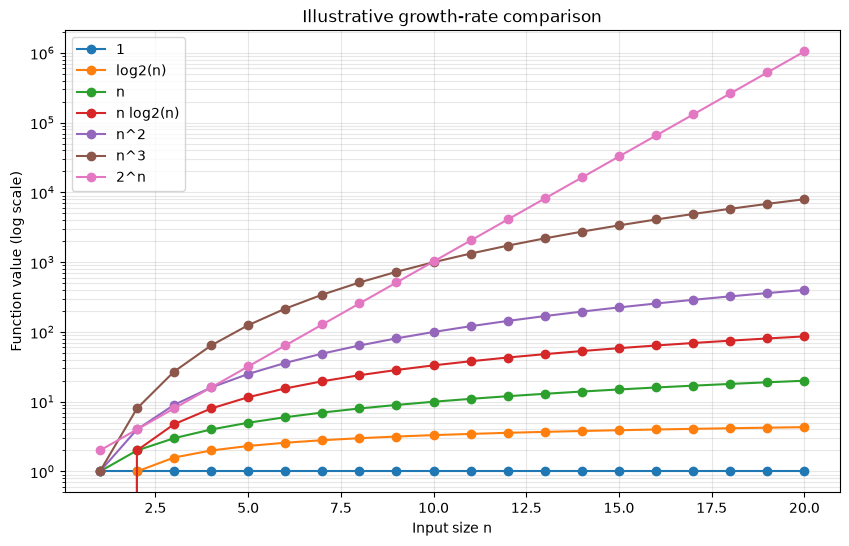

In [16]:
n = np.arange(1, 21)
growth = {
    "1": np.ones_like(n, dtype=float),
    "log2(n)": np.log2(n),
    "n": n.astype(float),
    "n log2(n)": n * np.log2(n),
    "n^2": n**2,
    "n^3": n**3,
    "2^n": 2.0**n,
}

plt.figure(figsize=(10, 6))
for label, values in growth.items():
    plt.plot(n, values, marker="o", label=label)
plt.yscale("log")
plt.xlabel("Input size n")
plt.ylabel("Function value (log scale)")
plt.title("Illustrative growth-rate comparison")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()

## 10. Big-Omega notation

We say $f(x)=\Omega(g(x))$ if there are positive constants $C$ and $k$ such that

\[

|f(x)| \ge C|g(x)| \quad \text{whenever } x>k.

\]

Big-Omega gives an asymptotic lower bound.

For example, $8n^3+5n^2+7=\Omega(n^3)$, because for positive $n$,

\[

8n^3+5n^2+7 \ge 8n^3.

\]

## 11. Big-Theta notation

We say $f(x)=\Theta(g(x))$ when both of the following hold:

\[

f(x)=O(g(x)) \quad \text{and} \quad f(x)=\Omega(g(x)).

\]

Thus Big-Theta gives a tight asymptotic bound.

For example,

\[

3n^2+5n+7=\Theta(n^2).

\]

### Comparison of asymptotic notations

| Notation | Interpretation | Bound |
|---|---|---|
| $O(g(n))$ | At most a constant multiple of $g(n)$, eventually | Upper |
| $\Omega(g(n))$ | At least a positive constant multiple of $g(n)$, eventually | Lower |
| $\Theta(g(n))$ | Both upper and lower bounds | Tight |

### 11.1 A practical polynomial dominant-term helper

For a polynomial with non-negative coefficients, the highest-degree term determines its asymptotic order. This helper is intentionally limited to such coefficient lists; it is not a general symbolic algebra system.

In [17]:
def polynomial_order_nonnegative(coefficients):
    """Coefficients ordered from highest degree to constant; all must be nonnegative."""
    if not coefficients:
        raise ValueError("Provide at least one coefficient")
    if any(c < 0 for c in coefficients):
        raise ValueError("This helper is restricted to non-negative coefficients")
    degree = len(coefficients) - 1
    for index, coefficient in enumerate(coefficients):
        if coefficient != 0:
            return degree - index
    return None  # zero polynomial

print("3n^4 + 2n^2 + 9 has order n^", polynomial_order_nonnegative([3, 0, 2, 0, 9]))
print("5n + 8 has order n^", polynomial_order_nonnegative([5, 8]))

3n^4 + 2n^2 + 9 has order n^ 4
5n + 8 has order n^ 1


## 12. Growth of combinations of functions

When an algorithm consists of subprocedures, their operation counts may be added or multiplied.

Useful rules from the growth-of-functions discussion:

- If $f_1=O(g_1)$ and $f_2=O(g_2)$, then $f_1+f_2=O(\max(|g_1|,|g_2|))$.
- If $f_1=O(g_1)$ and $f_2=O(g_2)$, then $f_1f_2=O(g_1g_2)$.

For example,

\[

O(n^2)+O(n)=O(n^2)

\]

and

\[

O(n)\cdot O(n)=O(n^2).

\]

A loop nested inside another loop often creates a product of iteration counts; consecutive independent loops often create a sum.

In [18]:
# Illustrative operation-count expressions
examples = pd.DataFrame([
    {"expression": "n^2 + n + 1", "dominant_order": "Theta(n^2)"},
    {"expression": "4n log2(n) + 7n", "dominant_order": "Theta(n log n)"},
    {"expression": "n * n", "dominant_order": "Theta(n^2)"},
    {"expression": "n^3 + 100n^2", "dominant_order": "Theta(n^3)"},
])
examples

,expression,dominant_order
0,n^2 + n + 1,Theta(n^2)
1,4n log2(n) + 7n,Theta(n log n)
2,n * n,Theta(n^2)
3,n^3 + 100n^2,Theta(n^3)


# Part III — Section 3.3: Complexity of Algorithms

## 13. Computational complexity

The chapter distinguishes:

- **Time complexity:** analysis of the number of basic operations used for an input of a given size.
- **Space complexity:** analysis of the memory required for an input of a given size.

The chapter explains both concepts but restricts its detailed analysis to time complexity. In this notebook, operation counts are the primary theoretical measure. Wall-clock timings are supplementary experimental observations.

### Why count operations rather than seconds?

Different computers and software environments execute operations at different speeds. Counting a selected basic operation gives a machine-independent model that can be analyzed mathematically.

## 14. Time complexity of searching

### Linear search

For a list of $n$ elements:
- Best case: the first element matches; one comparison.
- Worst case: the target is last or absent; $n$ comparisons.
- Worst-case growth: $\Theta(n)$.

### Binary search

Each iteration reduces the remaining interval to at most about half its previous size. After $k$ halvings, the interval has size at most approximately $n/2^k$. The number of halvings needed is proportional to $\log_2 n$.

- Best case: middle element matches immediately; $\Theta(1)$.
- Worst case: $\Theta(\log n)$.

In [19]:
def search_comparison_experiment(sizes):
    rows = []
    for size in sizes:
        values = list(range(size))
        target = size - 1  # worst-case direction for linear search
        _, linear_count = linear_search(values, target)
        _, binary_count = binary_search(values, target)
        rows.append({
            "n": size,
            "linear_comparisons": linear_count,
            "binary_comparisons": binary_count,
            "n_linear_bound": size,
            "log2_n": math.log2(size) if size > 1 else 0,
        })
    return pd.DataFrame(rows)

search_results = search_comparison_experiment([16, 32, 64, 128, 256, 512, 1024, 2048])
search_results

,n,linear_comparisons,binary_comparisons,n_linear_bound,log2_n
0,16,16,9,16,4.0
1,32,32,11,32,5.0
2,64,64,13,64,6.0
3,128,128,15,128,7.0
4,256,256,17,256,8.0
5,512,512,19,512,9.0
6,1024,1024,21,1024,10.0
7,2048,2048,23,2048,11.0


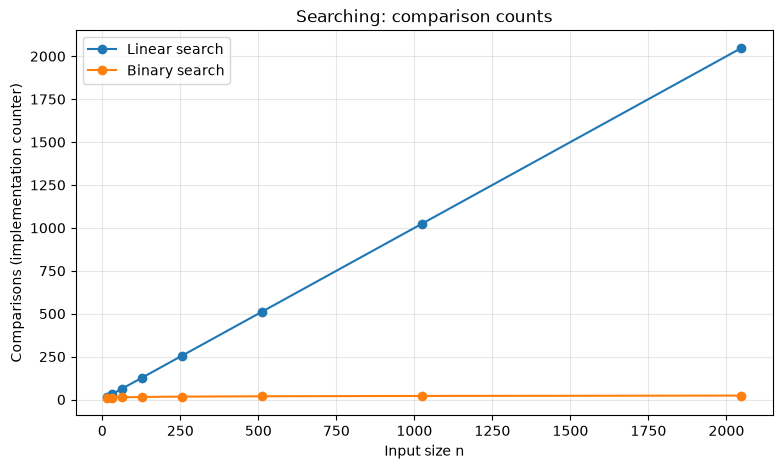

In [20]:
plt.figure(figsize=(9, 5))
plt.plot(search_results["n"], search_results["linear_comparisons"], marker="o", label="Linear search")
plt.plot(search_results["n"], search_results["binary_comparisons"], marker="o", label="Binary search")
plt.xlabel("Input size n")
plt.ylabel("Comparisons (implementation counter)")
plt.title("Searching: comparison counts")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

## 15. Time complexity of sorting

For the basic bubble sort, the number of comparisons is

\[

(n-1)+(n-2)+\cdots+1=\frac{n(n-1)}{2}.

\]

Therefore, the comparison count is $\Theta(n^2)$.

Insertion sort:
- Best case: each new element needs only one successful stopping comparison (for non-empty sorted input), giving $\Theta(n)$.
- Worst case: reverse order causes shifts through the sorted prefix, giving $\Theta(n^2)$.

In [21]:
def sorting_operation_experiment(sizes):
    rows = []
    for size in sizes:
        sorted_values = list(range(size))
        reverse_values = list(range(size, 0, -1))

        _, bubble_sorted_stats = bubble_sort(sorted_values)
        _, insertion_sorted_stats = insertion_sort(sorted_values)
        _, bubble_reverse_stats = bubble_sort(reverse_values)
        _, insertion_reverse_stats = insertion_sort(reverse_values)

        rows.append({
            "n": size,
            "bubble_sorted_comparisons": bubble_sorted_stats["comparisons"],
            "insertion_sorted_comparisons": insertion_sorted_stats["comparisons"],
            "bubble_reverse_comparisons": bubble_reverse_stats["comparisons"],
            "insertion_reverse_comparisons": insertion_reverse_stats["comparisons"],
            "bubble_theoretical_comparisons": size * (size - 1) // 2,
        })
    return pd.DataFrame(rows)

sorting_results = sorting_operation_experiment([10, 20, 40, 80, 120, 160])
sorting_results

,n,bubble_sorted_comparisons,insertion_sorted_comparisons,bubble_reverse_comparisons,insertion_reverse_comparisons,bubble_theoretical_comparisons
0,10,45,9,45,45,45
1,20,190,19,190,190,190
2,40,780,39,780,780,780
3,80,3160,79,3160,3160,3160
4,120,7140,119,7140,7140,7140
5,160,12720,159,12720,12720,12720


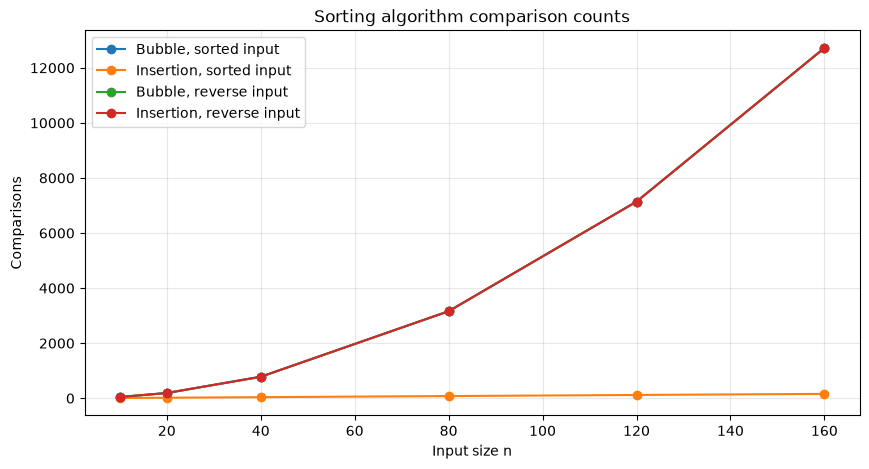

In [22]:
plt.figure(figsize=(10, 5))
plt.plot(sorting_results["n"], sorting_results["bubble_sorted_comparisons"], marker="o", label="Bubble, sorted input")
plt.plot(sorting_results["n"], sorting_results["insertion_sorted_comparisons"], marker="o", label="Insertion, sorted input")
plt.plot(sorting_results["n"], sorting_results["bubble_reverse_comparisons"], marker="o", label="Bubble, reverse input")
plt.plot(sorting_results["n"], sorting_results["insertion_reverse_comparisons"], marker="o", label="Insertion, reverse input")
plt.xlabel("Input size n")
plt.ylabel("Comparisons")
plt.title("Sorting algorithm comparison counts")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

## 16. Matrix multiplication and operation counting

For two $n \times n$ matrices using the standard triple-loop method:

- Each of the $n^2$ output entries is computed using $n$ multiplications.
- Total multiplications: $n^3$.
- Each output entry sums $n$ products using $n-1$ additions.
- Total additions: $n^2(n-1)$.

The total number of these arithmetic operations is $n^3+n^2(n-1)$, which is $\Theta(n^3)$.

In [23]:
def matrix_multiply_counted(A, B):
    A = np.asarray(A)
    B = np.asarray(B)
    if A.ndim != 2 or B.ndim != 2 or A.shape[1] != B.shape[0]:
        raise ValueError("Incompatible matrix dimensions")

    rows, shared = A.shape
    _, cols = B.shape
    C = np.zeros((rows, cols), dtype=np.result_type(A, B, float))
    multiplications = 0
    additions = 0

    for i in range(rows):
        for j in range(cols):
            total = 0
            for k in range(shared):
                total += A[i, k] * B[k, j]
                multiplications += 1
                if k > 0:
                    additions += 1
            C[i, j] = total

    return C, {"multiplications": multiplications, "additions": additions}


A = [[1, 2], [3, 4]]
B = [[5, 6], [7, 8]]
C, matrix_stats = matrix_multiply_counted(A, B)
print("Product:\n", C)
print("Operation counts:", matrix_stats)

Product:
 [[19. 22.]
 [43. 50.]]
Operation counts: {'multiplications': 8, 'additions': 4}


In [24]:
matrix_rows = []
for n_size in [2, 3, 4, 5, 10, 20]:
    matrix_rows.append({
        "n": n_size,
        "multiplications": n_size**3,
        "additions": n_size**2 * (n_size - 1),
        "total_counted_operations": n_size**3 + n_size**2 * (n_size - 1),
    })
pd.DataFrame(matrix_rows)

,n,multiplications,additions,total_counted_operations
0,2,8,4,12
1,3,27,18,45
2,4,64,48,112
3,5,125,100,225
4,10,1000,900,1900
5,20,8000,7600,15600


## 17. Matrix-chain multiplication: order matters

Matrix multiplication is associative, so the product of matrices can be parenthesized in different ways. The number of scalar multiplications can differ substantially.

For matrices with dimensions:
- $A_1: 30 \times 20$
- $A_2: 20 \times 40$
- $A_3: 40 \times 10$

Compare:
- $A_1(A_2A_3)$: $20\cdot40\cdot10 + 30\cdot20\cdot10 = 14{,}000$ multiplications.
- $(A_1A_2)A_3$: $30\cdot20\cdot40 + 30\cdot40\cdot10 = 36{,}000$ multiplications.

The same mathematical product can therefore have different computational costs depending on the order.

In [25]:
cost_a1_a2a3 = 20*40*10 + 30*20*10
cost_a1a2_a3 = 30*20*40 + 30*40*10
print("A1(A2A3):", cost_a1_a2a3)
print("(A1A2)A3:", cost_a1a2_a3)

A1(A2A3): 14000
(A1A2)A3: 36000


## 18. Algorithmic paradigms: brute force and greedy

An algorithmic paradigm is a general approach used to design algorithms.

### Brute force

Brute force uses a straightforward search through possible candidates or positions. The naive string matcher is an example: it tests every possible shift.

A second illustrative example is finding the closest pair by checking every pair of points. For $n$ points, there are $n(n-1)/2$ pairs, giving $\Theta(n^2)$ pair checks.

In [26]:
def closest_pair_brute_force(points):
    """Return closest pair and Euclidean distance; O(n^2) pair checks."""
    if len(points) < 2:
        raise ValueError("At least two points are required")

    best_pair = None
    best_distance = float("inf")
    comparisons = 0

    for i in range(len(points)):
        for j in range(i + 1, len(points)):
            comparisons += 1
            distance = math.dist(points[i], points[j])
            if distance < best_distance:
                best_distance = distance
                best_pair = (points[i], points[j])

    return best_pair, best_distance, comparisons


points = [(0, 0), (3, 4), (1, 1), (8, 8), (2, 2)]
closest_pair_brute_force(points)

(((0, 0), (1, 1)), 1.4142135623730951, 10)

### Greedy paradigm recap

The cashier and activity-scheduling implementations above illustrate greedy selection. The critical academic question is not merely whether a greedy algorithm returns a feasible result, but whether the chosen greedy rule is optimal for the specified problem.

### Other paradigms mentioned in the chapter

Rosen also points to divide-and-conquer, dynamic programming, backtracking and probabilistic algorithms as paradigms developed elsewhere in the book. They are not developed as full implementations in this Chapter 3 notebook.

## 19. Tractability and growth

A problem is often considered tractable when it can be solved by an algorithm whose running time is bounded by a polynomial in the input size. Exponential and factorial growth can become impractical rapidly as the input size increases.

This is an introductory comparison, not a complete theory of computational complexity classes.

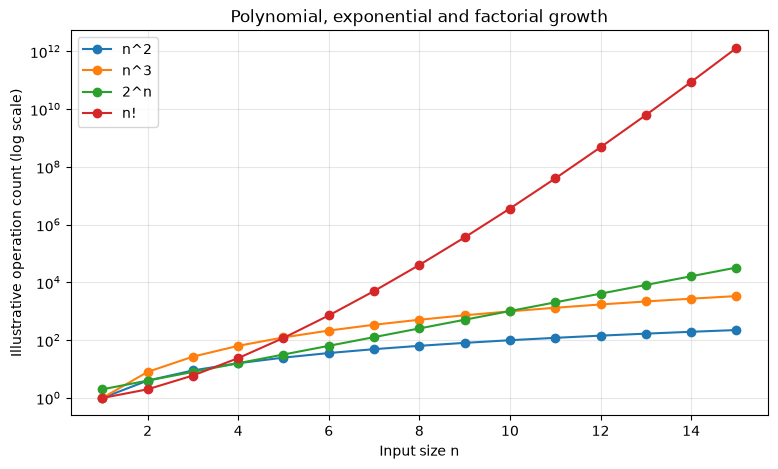

In [27]:
tractability_n = np.arange(1, 16)
plt.figure(figsize=(9, 5))
plt.plot(tractability_n, tractability_n**2, marker="o", label="n^2")
plt.plot(tractability_n, tractability_n**3, marker="o", label="n^3")
plt.plot(tractability_n, 2.0**tractability_n, marker="o", label="2^n")
plt.plot(tractability_n, [math.factorial(int(x)) for x in tractability_n],
         marker="o", label="n!")
plt.yscale("log")
plt.xlabel("Input size n")
plt.ylabel("Illustrative operation count (log scale)")
plt.title("Polynomial, exponential and factorial growth")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()

# Part IV — Experimental benchmarking

## 20. Measuring execution time

The theoretical analysis counts operations. The following experiments measure elapsed wall-clock time and should be interpreted carefully.

**Experimental precautions**
- Use the same computer and Python environment for comparisons.
- Repeat measurements and report a median.
- Keep input generation outside the timed region.
- Avoid very large quadratic inputs that may take excessive time.
- Do not infer an asymptotic class from a small number of timing observations alone.

In [28]:
def median_runtime(function, *args, repeats=5):
    durations = []
    for _ in range(repeats):
        start = time.perf_counter()
        function(*args)
        durations.append(time.perf_counter() - start)
    return statistics.median(durations)


def benchmark_searches(sizes, repeats=5):
    rows = []
    for size in sizes:
        values = list(range(size))
        target = size - 1
        linear_seconds = median_runtime(linear_search, values, target, repeats=repeats)
        binary_seconds = median_runtime(binary_search, values, target, repeats=repeats)
        rows.append({
            "n": size,
            "linear_seconds": linear_seconds,
            "binary_seconds": binary_seconds,
        })
    return pd.DataFrame(rows)


search_timing = benchmark_searches([100, 1000, 5000, 10000, 50000], repeats=5)
search_timing

,n,linear_seconds,binary_seconds
0,100,0.000007,0.000001
1,1000,0.000084,0.000002
2,5000,0.000457,0.000003
3,10000,0.000889,0.000003
4,50000,0.004629,0.000002


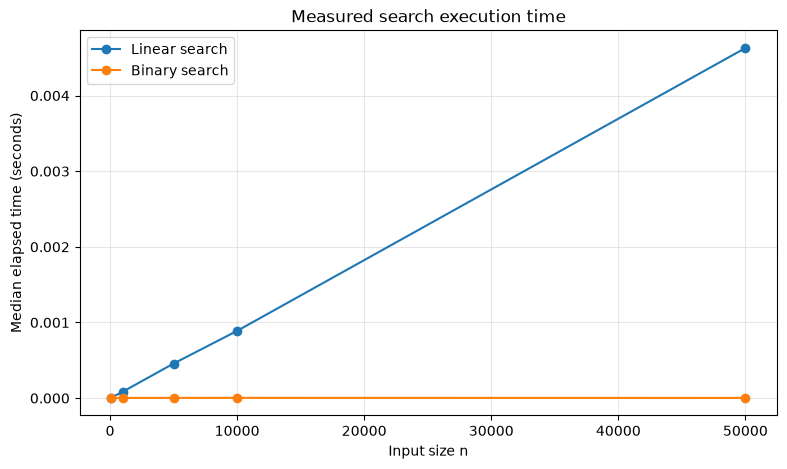

In [29]:
plt.figure(figsize=(9, 5))
plt.plot(search_timing["n"], search_timing["linear_seconds"], marker="o", label="Linear search")
plt.plot(search_timing["n"], search_timing["binary_seconds"], marker="o", label="Binary search")
plt.xlabel("Input size n")
plt.ylabel("Median elapsed time (seconds)")
plt.title("Measured search execution time")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

### 20.1 Sorting benchmark

Quadratic sorting algorithms are intentionally benchmarked only on moderate input sizes. Increase the sizes cautiously if your machine is fast enough.

In [30]:
def benchmark_sorts(sizes, repeats=3):
    rows = []
    for size in sizes:
        base = list(range(size))
        random.shuffle(base)

        bubble_seconds = median_runtime(bubble_sort, base, repeats=repeats)
        insertion_seconds = median_runtime(insertion_sort, base, repeats=repeats)

        rows.append({
            "n": size,
            "bubble_seconds": bubble_seconds,
            "insertion_seconds": insertion_seconds,
        })
    return pd.DataFrame(rows)


sort_timing = benchmark_sorts([50, 100, 200, 400, 600], repeats=3)
sort_timing

,n,bubble_seconds,insertion_seconds
0,50,0.000193,0.000113
1,100,0.000789,0.000518
2,200,0.002889,0.001984
3,400,0.013267,0.007716
4,600,0.029088,0.017223


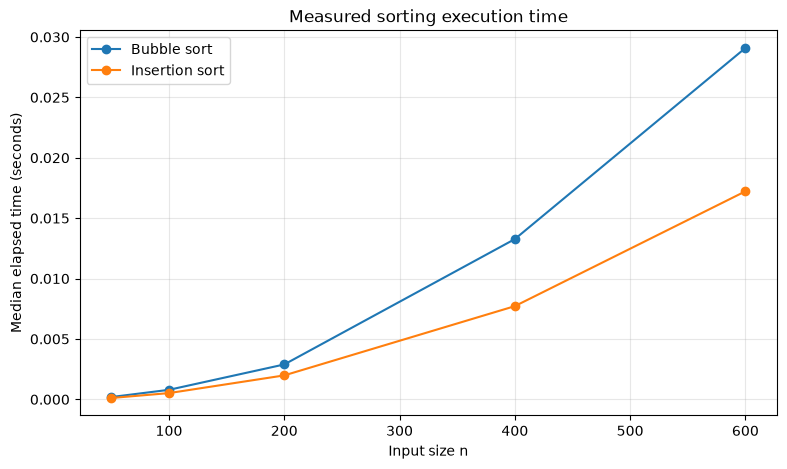

In [31]:
plt.figure(figsize=(9, 5))
plt.plot(sort_timing["n"], sort_timing["bubble_seconds"], marker="o", label="Bubble sort")
plt.plot(sort_timing["n"], sort_timing["insertion_seconds"], marker="o", label="Insertion sort")
plt.xlabel("Input size n")
plt.ylabel("Median elapsed time (seconds)")
plt.title("Measured sorting execution time")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

## 21. Theoretical versus experimental results

Use the following table to record observations after running the notebook on your own machine. Do not copy timing values from another computer.

| Algorithm | Theoretical worst-case growth | Counted operation | Experimental observation |
|---|---|---|---|
| Linear search | $\Theta(n)$ | Element comparisons | Complete after running |
| Binary search | $\Theta(\log n)$ | Element comparisons | Complete after running |
| Basic bubble sort | $\Theta(n^2)$ | Adjacent comparisons | Complete after running |
| Insertion sort | $\Theta(n^2)$ worst case; $\Theta(n)$ best case | Key comparisons and shifts | Complete after running |
| Naive string matcher | $O(nm)$ | Character comparisons | Complete after running |

**Interpretation:** Experimental time can be affected by interpreter overhead, memory behavior, CPU load and implementation details. Operation counts are more directly connected to the mathematical analysis.

# Part V — Validation and final observations

## 22. Automated correctness checks

These checks compare the implemented algorithms with trusted Python behavior on a range of test inputs.

In [32]:
# Maximum element tests
assert maximum_element([8, 4, 11, 3, 10])[0] == 11
assert maximum_element([-5, -2, -9])[0] == -2

# Searching tests
for values in [[], [1], [1, 2, 3], list(range(100))]:
    for target in [-1, 0, 1, 5, 99, 100]:
        expected = values.index(target) if target in values else -1
        assert linear_search(values, target)[0] == expected
        assert binary_search(values, target)[0] == expected

# Sorting tests
for _ in range(100):
    values = [random.randint(-50, 50) for _ in range(random.randint(0, 30))]
    assert bubble_sort(values)[0] == sorted(values)
    assert insertion_sort(values)[0] == sorted(values)

# String matching test
assert naive_string_match("eceyeye", "eye")[0] == [2, 4]

# Greedy examples
assert sum(count for _, count in cashier_change(67, [25, 10, 5, 1])) == 6
assert len(activity_selection([(1, 3, "A"), (2, 4, "B"), (3, 5, "C")])) == 2

# Matrix multiplication test
product, _ = matrix_multiply_counted([[1, 2], [3, 4]], [[5, 6], [7, 8]])
assert np.array_equal(product, np.array([[19, 22], [43, 50]]))

print("All correctness checks passed.")

All correctness checks passed.


## 23. Summary of Chapter 3 coverage

| Rosen section | Topic | Notebook coverage |
|---|---|---|
| 3.1 | Algorithm definition and properties | Explanation and maximum element |
| 3.1 | Searching | Linear and binary search |
| 3.1 | Sorting | Bubble and insertion sort |
| 3.1 | String matching | Naive matcher |
| 3.1 | Greedy algorithms | Cashier and activity scheduling |
| 3.1 | Halting problem | Contradiction explanation |
| 3.2 | Big-O | Definition and example |
| 3.2 | Growth estimates | Standard growth functions |
| 3.2 | Combinations | Sum and product rules |
| 3.2 | Big-Omega and Big-Theta | Definitions and examples |
| 3.3 | Complexity | Operation-count analysis |
| 3.3 | Searching and sorting | Comparison-count experiments |
| 3.3 | Matrix multiplication | Arithmetic operation counts |
| 3.3 | Algorithmic paradigms | Brute force and greedy |
| 3.3 | Tractability | Polynomial vs exponential/factorial growth |

## 24. Conclusion

This notebook has connected the mathematical study of algorithms with executable Python implementations and empirical experiments.

The central lessons are:

1. An algorithm must be precisely described and must satisfy the required correctness and termination properties.
2. Linear and binary search illustrate how different strategies lead to different growth rates.
3. Bubble sort and insertion sort demonstrate quadratic worst-case behavior, while insertion sort is linear on already sorted input.
4. Naive string matching and brute-force pair checking illustrate straightforward exhaustive approaches.
5. Greedy algorithms make local choices, but optimality must be established for the specific problem.
6. Big-O, Big-Omega and Big-Theta describe upper, lower and tight asymptotic bounds.
7. Operation counts provide a theoretical basis for complexity analysis; measured execution time provides complementary experimental evidence.

## 25. References

**Primary reference**

Rosen, Kenneth H. *Discrete Mathematics and Its Applications*. 8th Edition. McGraw-Hill Education. Chapter 3: Algorithms (Sections 3.1, 3.2 and 3.3).

**Technical documentation**

- Python documentation: https://docs.python.org/3/
- NumPy documentation: https://numpy.org/doc/
- pandas documentation: https://pandas.pydata.org/docs/
- Matplotlib documentation: https://matplotlib.org/stable/
- Jupyter documentation: https://docs.jupyter.org/

> Cite the textbook as the primary academic source in the final report. The technical documentation supports the implementation details.

# Supplementary Algorithms — Additional Topics

This supplementary section adds four algorithmic techniques related to the Chapter 3 themes. These additions do not replace the preceding explanations or implementations.

## 25. Selection sort

Selection sort repeatedly finds the smallest element in the unsorted suffix and swaps it into the next position. After pass $i$, the first $i+1$ positions contain the smallest elements in sorted order.

**Complexity:** best, average and worst-case time are $\Theta(n^2)$ comparisons; auxiliary space is $O(1)$. The number of comparisons is independent of the input order.


In [33]:
def selection_sort(values):
    """Return a sorted copy and the number of element comparisons."""
    arr = list(values)
    comparisons = 0
    n = len(arr)
    for i in range(n - 1):
        min_index = i
        for j in range(i + 1, n):
            comparisons += 1
            if arr[j] < arr[min_index]:
                min_index = j
        if min_index != i:
            arr[i], arr[min_index] = arr[min_index], arr[i]
    return arr, comparisons

selection_sort([64, 25, 12, 22, 11])

([11, 12, 22, 25, 64], 10)

## 26. Binary insertion sort

Binary insertion sort is an insertion-sort variant. It uses binary search to find the insertion position in the already-sorted prefix, then shifts elements to make room for the key.

Binary search reduces the number of comparisons used to locate an insertion point, but shifting can still move a linear number of elements per pass.

**Complexity:** $O(n\log n)$ comparisons to locate insertion positions, but $O(n^2)$ worst-case element moves; overall worst-case running time remains $\Theta(n^2)$. Auxiliary space is $O(1)$ for this in-place implementation.


In [34]:
def binary_insertion_sort(values):
    """Return a sorted copy, comparison count, and shift count."""
    arr = list(values)
    comparisons = 0
    shifts = 0
    for i in range(1, len(arr)):
        key = arr[i]
        low, high = 0, i
        # Upper-bound search keeps the sort stable for equal values.
        while low < high:
            mid = (low + high) // 2
            comparisons += 1
            if key < arr[mid]:
                high = mid
            else:
                low = mid + 1
        j = i
        while j > low:
            arr[j] = arr[j - 1]
            shifts += 1
            j -= 1
        arr[low] = key
    return arr, comparisons, shifts

binary_insertion_sort([5, 2, 4, 6, 1, 3])

([1, 2, 3, 4, 5, 6], 10, 9)

## 27. Boyer–Moore majority vote algorithm

The Boyer–Moore majority vote algorithm finds a candidate for a majority element: a value that occurs more than $n/2$ times. It maintains a candidate and a counter. A matching value increments the counter; a different value decrements it; when the counter reaches zero, the next value becomes the candidate.

The candidate must be verified in a second pass because a majority element may not exist.

**Complexity:** $O(n)$ time and $O(1)$ auxiliary space.


In [35]:
def boyer_moore_majority(values):
    """Return the majority element, or None if no majority exists."""
    candidate = None
    count = 0
    for value in values:
        if count == 0:
            candidate = value
            count = 1
        elif value == candidate:
            count += 1
        else:
            count -= 1

    if candidate is None:
        return None
    if sum(1 for value in values if value == candidate) > len(values) // 2:
        return candidate
    return None

print(boyer_moore_majority([2, 2, 1, 2, 3, 2, 2]))
print(boyer_moore_majority([1, 2, 3, 1, 2, 3]))

2
None


## 28. Stable matching — deferred acceptance algorithm

The stable matching problem pairs members of two equally sized groups according to preference lists. A matching is stable if there is no unmatched pair who would both prefer each other over their assigned partners.

In the deferred acceptance (Gale–Shapley) algorithm, members of the proposing group make proposals in preference order. A receiver tentatively keeps the proposal it prefers most and rejects any less-preferred proposal. Rejected proposers continue with their next choice. The process ends when no proposer remains unmatched with an available choice.

**Complexity:** with $n$ proposers and $n$ receivers, each proposer makes at most $n$ proposals, so the algorithm runs in $O(n^2)$ time with preference ranks precomputed or efficiently compared.


In [36]:
def deferred_acceptance(proposer_preferences, receiver_preferences):
    """Return a stable proposer-to-receiver matching.

    Both arguments map each participant to a complete preference list.
    The two groups must have the same members count and unique names.
    """
    proposers = list(proposer_preferences)
    receivers = list(receiver_preferences)
    if len(proposers) != len(receivers):
        raise ValueError("The two groups must have equal size.")
    receiver_set = set(receivers)
    proposer_set = set(proposers)
    for proposer in proposers:
        if set(proposer_preferences[proposer]) != receiver_set or len(proposer_preferences[proposer]) != len(receivers):
            raise ValueError("Each proposer must rank every receiver exactly once.")
    for receiver in receivers:
        if set(receiver_preferences[receiver]) != proposer_set or len(receiver_preferences[receiver]) != len(proposers):
            raise ValueError("Each receiver must rank every proposer exactly once.")

    receiver_rank = {
        receiver: {proposer: rank for rank, proposer in enumerate(receiver_preferences[receiver])}
        for receiver in receivers
    }
    next_choice = {proposer: 0 for proposer in proposers}
    free = list(proposers)
    receiver_partner = {receiver: None for receiver in receivers}

    while free:
        proposer = free.pop(0)
        preferences = proposer_preferences[proposer]
        if next_choice[proposer] >= len(preferences):
            continue
        receiver = preferences[next_choice[proposer]]
        next_choice[proposer] += 1
        current = receiver_partner[receiver]
        if current is None:
            receiver_partner[receiver] = proposer
        elif receiver_rank[receiver][proposer] < receiver_rank[receiver][current]:
            receiver_partner[receiver] = proposer
            free.append(current)
        else:
            free.append(proposer)

    return {proposer: receiver for receiver, proposer in receiver_partner.items() if proposer is not None}

proposer_preferences = {
    "A": ["X", "Y", "Z"],
    "B": ["Y", "X", "Z"],
    "C": ["Y", "Z", "X"],
}
receiver_preferences = {
    "X": ["B", "A", "C"],
    "Y": ["A", "B", "C"],
    "Z": ["A", "C", "B"],
}
deferred_acceptance(proposer_preferences, receiver_preferences)

{'A': 'X', 'B': 'Y', 'C': 'Z'}

## 29. Additional correctness checks

Run these assertions after the supplementary implementations. They check sorting results, majority-element verification and the deferred-acceptance matching.

In [37]:
assert selection_sort([64, 25, 12, 22, 11])[0] == [11, 12, 22, 25, 64]
assert selection_sort([])[0] == []
assert binary_insertion_sort([5, 2, 4, 6, 1, 3])[0] == [1, 2, 3, 4, 5, 6]
assert binary_insertion_sort([2, 2, 1])[0] == [1, 2, 2]
assert boyer_moore_majority([2, 2, 1, 2, 3, 2, 2]) == 2
assert boyer_moore_majority([1, 2, 3, 1, 2, 3]) is None
matching = deferred_acceptance(proposer_preferences, receiver_preferences)
assert len(matching) == 3 and len(set(matching.values())) == 3
print("All supplementary algorithm checks passed.")

All supplementary algorithm checks passed.
